## Interval Analysis

In [ ]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 50)
        self.fc2 = nn.Linear(50, 50)
        self.fc3 = nn.Linear(50, 50)
        self.fc4 = nn.Linear(50, 10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 461kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.60MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=50, bias=True)
    (fc2): Linear(in_features=50, out_features=50, bias=True)
    (fc3): Linear(in_features=50, out_features=50, bias=True)
    (fc4): Linear(in_features=50, out_features=10, bias=True)
  )
)

In [ ]:
def train_model(model, num_epochs, ibp=False):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
    start_time = time.perf_counter()

    for epoch in range(num_epochs):
        if ibp:
            progress = epoch / (num_epochs - 1)
            kappa = 1.0 - 0.5 * progress
            epsilon = 0.1 * progress
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            if ibp:
                standard_loss = criterion(outputs, labels)
                robust_loss = ibp_robust_loss(model, images, labels, epsilon)
                loss = kappa * standard_loss + (1 - kappa) * robust_loss
            else:
                loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')
        if ibp:
            print(f'Kappa: {kappa:.3f}, Epsilon: {epsilon:.3f}')

    training_time = time.perf_counter() - start_time
    print(f'Training Time: {training_time:.2f} seconds')
    return training_time

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        accuracy = 100 * correct / total
        print(f'Accuracy: {accuracy:.2f}%')
        return accuracy

In [ ]:
torch.manual_seed(42)
ibp_model = nn.Sequential(Normalize(), Net()).to(device)
ibp_training_time = train_model(ibp_model, 15, ibp=True)
ibp_accuracy = test_model(ibp_model)

Epoch 1/15, Loss: 1.328
Kappa: 1.000, Epsilon: 0.000
Epoch 2/15, Loss: 0.554
Kappa: 0.964, Epsilon: 0.007
Epoch 3/15, Loss: 0.559
Kappa: 0.929, Epsilon: 0.014
Epoch 4/15, Loss: 0.527
Kappa: 0.893, Epsilon: 0.021
Epoch 5/15, Loss: 0.516
Kappa: 0.857, Epsilon: 0.029
Epoch 6/15, Loss: 0.525
Kappa: 0.821, Epsilon: 0.036
Epoch 7/15, Loss: 0.544
Kappa: 0.786, Epsilon: 0.043
Epoch 8/15, Loss: 0.567
Kappa: 0.750, Epsilon: 0.050
Epoch 9/15, Loss: 0.596
Kappa: 0.714, Epsilon: 0.057
Epoch 10/15, Loss: 0.631
Kappa: 0.679, Epsilon: 0.064
Epoch 11/15, Loss: 0.671
Kappa: 0.643, Epsilon: 0.071
Epoch 12/15, Loss: 0.717
Kappa: 0.607, Epsilon: 0.079
Epoch 13/15, Loss: 0.769
Kappa: 0.571, Epsilon: 0.086
Epoch 14/15, Loss: 0.826
Kappa: 0.536, Epsilon: 0.093
Epoch 15/15, Loss: 0.890
Kappa: 0.500, Epsilon: 0.100
Training Time: 184.74 seconds
Accuracy: 90.48%


In [ ]:
training_time = train_model(model, 15)
accuracy = test_model(model)

Epoch 1/15, Loss: 1.328
Epoch 2/15, Loss: 0.379
Epoch 3/15, Loss: 0.289
Epoch 4/15, Loss: 0.237
Epoch 5/15, Loss: 0.200
Epoch 6/15, Loss: 0.175
Epoch 7/15, Loss: 0.156
Epoch 8/15, Loss: 0.142
Epoch 9/15, Loss: 0.131
Epoch 10/15, Loss: 0.120
Epoch 11/15, Loss: 0.111
Epoch 12/15, Loss: 0.105
Epoch 13/15, Loss: 0.098
Epoch 14/15, Loss: 0.092
Epoch 15/15, Loss: 0.087
Training Time: 121.75 seconds
Accuracy on images: 96.66%


In [ ]:
def pgd_attack(model, images, labels, epsilon=0.1, alpha=0.01, steps=40):
    original_images = images.detach()
    adv_images = original_images + torch.empty_like(images).uniform_(-epsilon, epsilon)
    adv_images = torch.clamp(adv_images, 0, 1)

    for _ in range(steps):
        adv_images = adv_images.detach().requires_grad_(True)
        outputs = model(adv_images)
        loss = F.cross_entropy(outputs, labels)
        grad = torch.autograd.grad(loss, adv_images)[0]
        adv_images = adv_images.detach() + alpha * grad.sign()
        adv_images = torch.max(torch.min(adv_images, original_images + epsilon), original_images - epsilon)
        adv_images = torch.clamp(adv_images, 0, 1)

    return adv_images.detach()


def evaluate_pgd_accuracy(model, test_loader, epsilon=0.1):
    model.eval()
    correct = 0
    total = 0

    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        adv_images = pgd_attack(model, images, labels, epsilon)

        with torch.no_grad():
            outputs = model(adv_images)
            predicted = outputs.argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    return accuracy


In [ ]:
standard_pgd_accuracy = evaluate_pgd_accuracy(model, test_loader, epsilon=0.1)
ibp_pgd_accuracy = evaluate_pgd_accuracy(ibp_model, test_loader, epsilon=0.1)

print(f"Standard PGD Accuracy: {standard_pgd_accuracy:.2f}%")
print(f"IBP PGD Accuracy: {ibp_pgd_accuracy:.2f}%")

Standard PGD Accuracy: 6.27%
IBP PGD Accuracy: 72.15%


### Write the interval analysis for the simple model

In [ ]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation
def get_input_bounds(images, epsilon):
    lower = torch.clamp(images - epsilon, min=0.0, max=1.0)
    upper = torch.clamp(images + epsilon, min=0.0, max=1.0)

    return lower, upper

def linear_interval(lower, upper, layer):
    weight = layer.weight
    bias = layer.bias

    pos = torch.clamp(layer.weight, min=0)
    neg = torch.clamp(layer.weight, max=0)

    lower2 = torch.nn.functional.linear(lower, pos) + torch.nn.functional.linear(upper, neg) + bias
    upper2 = torch.nn.functional.linear(upper, pos) + torch.nn.functional.linear(lower, neg) + bias

    return lower2, upper2

def interval_bound_propagation(model, images, epsilon):
    lower, upper = get_input_bounds(images, epsilon)

    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081

    lower = lower.view(lower.size(0), -1)
    upper = upper.view(upper.size(0), -1)

    lower, upper = linear_interval(lower, upper, model[1].fc)
    lower, upper = F.relu(lower), F.relu(upper)

    lower, upper = linear_interval(lower, upper, model[1].fc2)
    lower, upper = F.relu(lower), F.relu(upper)

    lower, upper = linear_interval(lower, upper, model[1].fc3)
    lower, upper = F.relu(lower), F.relu(upper)

    lower, upper = linear_interval(lower, upper, model[1].fc4)

    return lower, upper

def robust_verification(lower, upper, labels):
    correct_lower = lower[torch.arange(labels.size(0), device=labels.device), labels]
    margins = correct_lower.unsqueeze(1) - upper
    margins[torch.arange(labels.size(0), device=labels.device), labels] = float("inf")
    verified = (margins >= 0).all(dim=1)

    return verified

def difference_interval_bound_propagation(model, images, labels, epsilon):
    lower, upper = get_input_bounds(images, epsilon)

    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081

    lower = lower.view(lower.size(0), -1)
    upper = upper.view(upper.size(0), -1)

    lower, upper = linear_interval(lower, upper, model[1].fc)
    lower, upper = F.relu(lower), F.relu(upper)

    lower, upper = linear_interval(lower, upper, model[1].fc2)
    lower, upper = F.relu(lower), F.relu(upper)

    lower, upper = linear_interval(lower, upper, model[1].fc3)
    lower, upper = F.relu(lower), F.relu(upper)

    weight = model[1].fc4.weight
    bias = model[1].fc4.bias

    correct_weight = weight[labels]
    correct_bias = bias[labels]

    diff_weight = correct_weight.unsqueeze(1) - weight.unsqueeze(0)
    diff_bias = correct_bias.unsqueeze(1) - bias.unsqueeze(0)

    weight_pos = torch.clamp(diff_weight, min=0)
    weight_neg = torch.clamp(diff_weight, max=0)

    diff_lower = torch.bmm(weight_pos, lower.unsqueeze(2)).squeeze(2) + torch.bmm(weight_neg, upper.unsqueeze(2)).squeeze(2) + diff_bias

    return diff_lower


def ibp_robust_loss(model, images, labels, epsilon):
    diff_lower = difference_interval_bound_propagation(model, images, labels, epsilon)
    worst_case_logits = -diff_lower
    worst_case_logits = worst_case_logits.scatter(1, labels.unsqueeze(1), 0.0)

    return F.cross_entropy(worst_case_logits, labels)


def difference_bounds_verification(diff_lower, labels):
    diff_lower = diff_lower.clone()
    diff_lower[torch.arange(labels.size(0), device=labels.device), labels] = float("inf")
    verified = (diff_lower >= 0).all(dim=1)

    return verified

def evaluate_diff_layer_accuracy(model, test_loader, epsilon):
    model.eval()
    verified_count = 0
    total_count = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            diff_lower = difference_interval_bound_propagation(model, images, labels, epsilon)
            verified = difference_bounds_verification(diff_lower, labels)
            verified_count += verified.sum().item()
            total_count += labels.size(0)

    return 100.0 * verified_count / total_count

In [ ]:
epsilons = np.linspace(0.01, 0.1, 10)
ibp_verified_accuracies = []

for epsilon in epsilons:
    accuracy = evaluate_diff_layer_accuracy(ibp_model, test_loader, epsilon)
    ibp_verified_accuracies.append(accuracy)
    print(f"Epsilon: {epsilon:.2f}, Verified Accuracy: {accuracy:.2f}%")

Epsilon: 0.01, Verified Accuracy: 88.91%
Epsilon: 0.02, Verified Accuracy: 87.23%
Epsilon: 0.03, Verified Accuracy: 85.32%
Epsilon: 0.04, Verified Accuracy: 83.15%
Epsilon: 0.05, Verified Accuracy: 80.56%
Epsilon: 0.06, Verified Accuracy: 77.84%
Epsilon: 0.07, Verified Accuracy: 75.15%
Epsilon: 0.08, Verified Accuracy: 71.69%
Epsilon: 0.09, Verified Accuracy: 67.68%
Epsilon: 0.10, Verified Accuracy: 63.08%


In [ ]:
epsilons = np.linspace(0.01, 0.1, 10)
verified_accuracies = []

for epsilon in epsilons:
    accuracy = evaluate_verified_accuracy(model, test_loader, epsilon)
    verified_accuracies.append(accuracy)

    print(f"Epsilon: {epsilon:.2f}, Verified Accuracy: {accuracy:.2f}%")

Epsilon: 0.01, Verified Accuracy: 49.59%
Epsilon: 0.02, Verified Accuracy: 5.30%
Epsilon: 0.03, Verified Accuracy: 0.20%
Epsilon: 0.04, Verified Accuracy: 0.00%
Epsilon: 0.05, Verified Accuracy: 0.00%
Epsilon: 0.06, Verified Accuracy: 0.00%
Epsilon: 0.07, Verified Accuracy: 0.00%
Epsilon: 0.08, Verified Accuracy: 0.00%
Epsilon: 0.09, Verified Accuracy: 0.00%
Epsilon: 0.10, Verified Accuracy: 0.00%


In [ ]:
epsilon = 0.1
num_examples = 5
ibp_model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    clean_pred = ibp_model(images).argmax(dim=1)
    diff_lower = difference_interval_bound_propagation(ibp_model, images, labels, epsilon)
    verified = difference_bounds_verification(diff_lower, labels)

mask = (clean_pred == labels) & (~verified)
candidate_images = images[mask]
candidate_labels = labels[mask]
adv_images = pgd_attack(ibp_model, candidate_images, candidate_labels, epsilon=epsilon, alpha=0.01, steps=40)

with torch.no_grad():
    adv_pred = ibp_model(adv_images).argmax(dim=1)

# Keep only successful adversarial attacks
successful = adv_pred != candidate_labels

originals = candidate_images[successful][:num_examples]
adversarials = adv_images[successful][:num_examples]
true_labels = candidate_labels[successful][:num_examples]
pred_labels = adv_pred[successful][:num_examples]

print(f"Uncertified candidates: {len(candidate_images)}")
print(f"Successful attacks: {successful.sum().item()}")
print(f"Examples selected: {len(originals)}")


Uncertified candidates: 17
Successful attacks: 11
Examples selected: 5


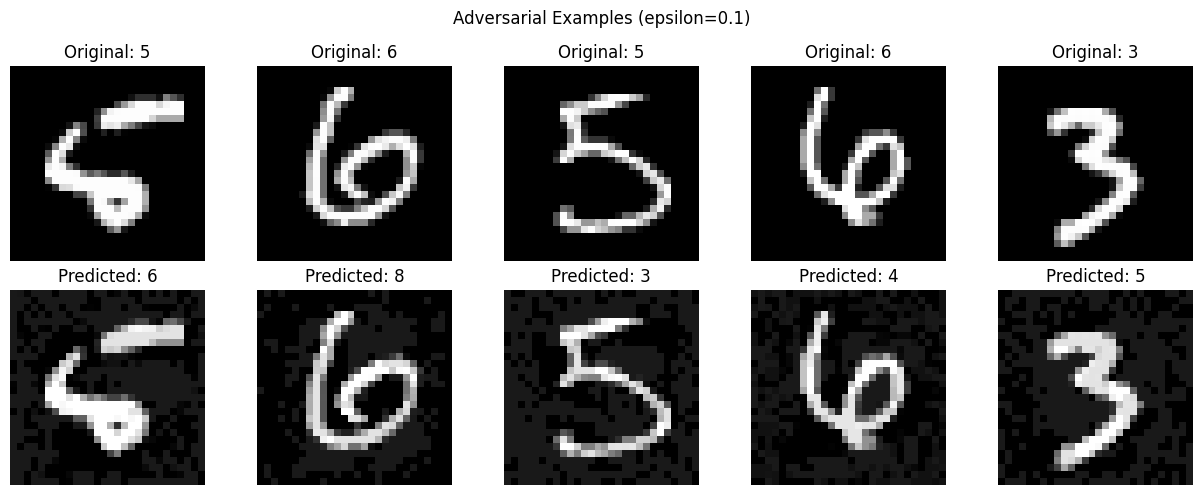

In [ ]:
n = len(originals)

if n > 0:
    fig, axes = plt.subplots(2, n, figsize=(2.5*n, 5))
    axes = np.array(axes).reshape(2, n)

    for i in range(n):
        axes[0, i].imshow(originals[i].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[0, i].set_title(f"Original: {true_labels[i].item()}")
        axes[0, i].axis("off")
        axes[1, i].imshow(adversarials[i].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[1, i].set_title(f"Predicted: {pred_labels[i].item()}")
        axes[1, i].axis("off")

    plt.suptitle(f"Adversarial Examples (epsilon={epsilon})")
    plt.tight_layout()
    plt.savefig("adversarial_examples.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Not found.")


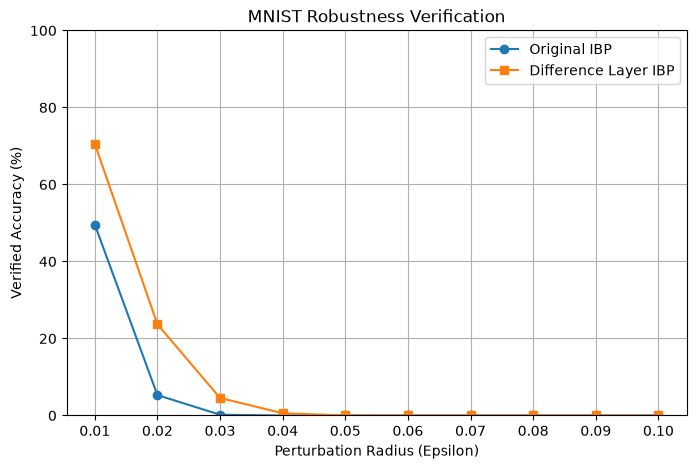

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    epsilons,
    verified_accuracies,
    marker='o',
    label='Original IBP'
)

plt.plot(
    epsilons,
    difference_verified_accuracies,
    marker='s',
    label='Difference Layer IBP'
)

plt.xlabel("Perturbation Radius (Epsilon)")
plt.ylabel("Verified Accuracy (%)")
plt.title("MNIST Robustness Verification")
plt.xticks(epsilons)
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.show()